In [7]:
!pip install python-mlb-statsapi pandas numpy pymc arviz matplotlib seaborn tqdm

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 3.3 MB/s  0:00:00 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5/5 [python-mlb-statsapi]thon-mlb-statsapi]

[notice] A new release of pip is available: 25.2 -> 26.1
[notice] To update, run: pip install --upgrade pip


In [10]:
!pip install MLB-StatsAPI


[notice] A new release of pip is available: 25.2 -> 26.1
[notice] To update, run: pip install --upgrade pip


In [1]:
import sys
print(sys.executable)
import sys
!{sys.executable} -m pip install MLB-StatsAPI

/usr/local/bin/python3

[notice] A new release of pip is available: 25.2 -> 26.1
[notice] To update, run: pip install --upgrade pip


In [25]:
import statsapi
import pandas as pd

# Map stadium aliases / renamed parks to one canonical name
stadium_name_map = {
    "Minute Maid Park": "Daikin Park",   # Astros
    "Daikin Park": "Daikin Park",

    "Oakland Coliseum": "Sutter Health Park",  # A's franchise continuity
    "Sutter Health Park": "Sutter Health Park"
}

# Official MLB stadiums (canonical names)
official_mlb_stadiums = {
    "Angel Stadium",
    "Busch Stadium",
    "Chase Field",
    "Citi Field",
    "Citizens Bank Park",
    "Comerica Park",
    "Coors Field",
    "Daikin Park",
    "Dodger Stadium",
    "Fenway Park",
    "George M. Steinbrenner Field",
    "Globe Life Field",
    "Great American Ball Park",
    "Guaranteed Rate Field",
    "Kauffman Stadium",
    "loanDepot park",
    "Nationals Park",
    "Oracle Park",
    "Oriole Park at Camden Yards",
    "Petco Park",
    "PNC Park",
    "Progressive Field",
    "Rogers Centre",
    "Sutter Health Park",
    "T-Mobile Park",
    "Target Field",
    "Truist Park",
    "Wrigley Field",
    "Yankee Stadium",
    "American Family Field"
}

def extract_fast(season):
    schedule = statsapi.schedule(
        start_date=f"{season}-03-20",
        end_date=f"{season}-10-01"
    )

    data = []

    for game in schedule:

        # Only completed games
        if game['status'] != 'Final':
            continue

        # Normalize stadium names
        raw_venue = game['venue_name']
        venue = stadium_name_map.get(raw_venue, raw_venue)

        # Keep only MLB home stadiums
        if venue not in official_mlb_stadiums:
            continue

        data.append({
            "game_id": game['game_id'],
            "venue": venue,
            "team": game['home_name'],
            "runs": game['home_score']
        })

        data.append({
            "game_id": game['game_id'],
            "venue": venue,
            "team": game['away_name'],
            "runs": game['away_score']
        })

    return pd.DataFrame(data)

# Pull seasons
df_2024 = extract_fast(2024)
df_2025 = extract_fast(2025)

# Combine
df = pd.concat([df_2024, df_2025], ignore_index=True)

print("Total rows:", len(df))
print("Unique venues:", df['venue'].nunique())
print(sorted(df['venue'].unique()))

# Save
df.to_csv("mlb_runs_data_30.csv", index=False)

Total rows: 9462
Unique venues: 30
['American Family Field', 'Angel Stadium', 'Busch Stadium', 'Chase Field', 'Citi Field', 'Citizens Bank Park', 'Comerica Park', 'Coors Field', 'Daikin Park', 'Dodger Stadium', 'Fenway Park', 'George M. Steinbrenner Field', 'Globe Life Field', 'Great American Ball Park', 'Guaranteed Rate Field', 'Kauffman Stadium', 'Nationals Park', 'Oracle Park', 'Oriole Park at Camden Yards', 'PNC Park', 'Petco Park', 'Progressive Field', 'Rogers Centre', 'Sutter Health Park', 'T-Mobile Park', 'Target Field', 'Truist Park', 'Wrigley Field', 'Yankee Stadium', 'loanDepot park']


In [26]:
import statsapi

games = statsapi.schedule(start_date="2024-04-01", end_date="2024-04-03")
print(len(games))
print(games[:2])

43
[{'game_id': 746817, 'game_datetime': '2024-04-01T18:10:00Z', 'game_date': '2024-04-01', 'game_type': 'R', 'status': 'Completed Early', 'away_name': 'Atlanta Braves', 'home_name': 'Chicago White Sox', 'away_id': 144, 'home_id': 145, 'doubleheader': 'N', 'game_num': 1, 'home_probable_pitcher': 'Chris Flexen', 'away_probable_pitcher': 'Charlie Morton', 'home_pitcher_note': '', 'away_pitcher_note': '', 'away_score': 9, 'home_score': 0, 'current_inning': 8, 'inning_state': 'Bottom', 'venue_id': 4, 'venue_name': 'Guaranteed Rate Field', 'national_broadcasts': [], 'series_status': 'ATL leads 1-0', 'summary': '2024-04-01 - Atlanta Braves @ Chicago White Sox (Completed Early)'}, {'game_id': 746899, 'game_datetime': '2024-04-01T18:20:00Z', 'game_date': '2024-04-01', 'game_type': 'R', 'status': 'Final', 'away_name': 'Colorado Rockies', 'home_name': 'Chicago Cubs', 'away_id': 115, 'home_id': 112, 'doubleheader': 'N', 'game_num': 1, 'home_probable_pitcher': 'Shota Imanaga', 'away_probable_pitch

In [27]:
import pandas as pd

df = pd.read_csv("mlb_runs_data_30.csv")

# Encode ballparks
df['park_id'] = df['venue'].astype('category').cat.codes
parks = df['venue'].astype('category').cat.categories

y = df['runs'].values
park_idx = df['park_id'].values
J = len(parks)

print(f"Number of parks: {J}")
print(df.head())

Number of parks: 30
   game_id                         venue                team  runs  park_id
0   747887  George M. Steinbrenner Field    New York Yankees    12       11
1   747887  George M. Steinbrenner Field  Pittsburgh Pirates     0       11
2   747863  George M. Steinbrenner Field    New York Yankees     5       11
3   747863  George M. Steinbrenner Field       New York Mets     3       11
4   747837  George M. Steinbrenner Field    New York Yankees     6       11


Baysian Hierachical Model

In [28]:
import pymc as pm
import numpy as np

with pm.Model() as model:

    # Priors
    alpha = pm.Normal("alpha", mu=0, sigma=1)
    sigma = pm.HalfCauchy("sigma", beta=2)

    beta = pm.Normal("beta", mu=0, sigma=sigma, shape=J)

    # Expected value
    mu = pm.math.exp(alpha + beta[park_idx])

    # Likelihood
    y_obs = pm.Poisson("y_obs", mu=mu, observed=y)

    # MCMC sampling
    trace = pm.sample(
        draws=2000,
        tune=1000,
        target_accept=0.9,
        return_inferencedata=True
    )

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [alpha, sigma, beta]


/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/rich/live.py:256: UserWarning: 
install "ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

Sampling 4 chains for 1_000 tune and 2_000 draw iterations (4_000 + 8_000 draws total) took 5 seconds.


Posterior Summary

In [29]:
import arviz as az

summary = az.summary(trace, var_names=["alpha", "sigma", "beta"])
print(summary)

           mean     sd  hdi_3%  hdi_97%  mcse_mean  mcse_sd  ess_bulk  \
alpha     1.482  0.016   1.453    1.513        0.0      0.0    1767.0   
sigma     0.083  0.013   0.060    0.107        0.0      0.0    9940.0   
beta[0]  -0.030  0.030  -0.085    0.026        0.0      0.0    4474.0   
beta[1]   0.037  0.028  -0.017    0.088        0.0      0.0    4293.0   
beta[2]  -0.040  0.030  -0.095    0.018        0.0      0.0    4924.0   
beta[3]   0.133  0.028   0.083    0.190        0.0      0.0    4450.0   
beta[4]   0.019  0.029  -0.036    0.074        0.0      0.0    4745.0   
beta[5]   0.042  0.029  -0.011    0.097        0.0      0.0    4312.0   
beta[6]  -0.008  0.029  -0.062    0.047        0.0      0.0    4520.0   
beta[7]   0.221  0.028   0.166    0.271        0.0      0.0    4313.0   
beta[8]  -0.028  0.029  -0.084    0.025        0.0      0.0    5215.0   
beta[9]   0.059  0.028   0.009    0.114        0.0      0.0    4671.0   
beta[10]  0.037  0.029  -0.017    0.091        0.0 

Convergence

array([[<Axes: title={'center': 'alpha'}>,
        <Axes: title={'center': 'alpha'}>],
       [<Axes: title={'center': 'sigma'}>,
        <Axes: title={'center': 'sigma'}>]], dtype=object)

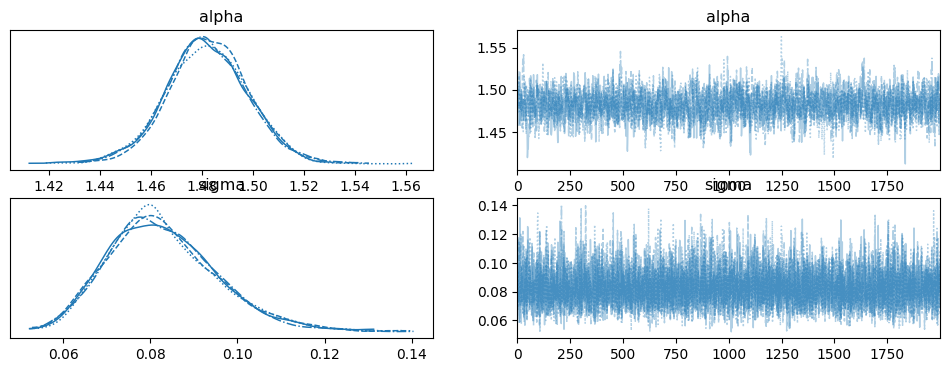

In [30]:
az.plot_trace(trace, var_names=["alpha", "sigma"])

In [31]:
print(az.rhat(trace))

<xarray.Dataset> Size: 496B
Dimensions:     (beta_dim_0: 30)
Coordinates:
  * beta_dim_0  (beta_dim_0) int64 240B 0 1 2 3 4 5 6 7 ... 23 24 25 26 27 28 29
Data variables:
    alpha       float64 8B 1.002
    beta        (beta_dim_0) float64 240B 1.001 1.001 1.0 ... 0.9999 1.0 1.001
    sigma       float64 8B 1.001
Attributes:
    created_at:                 2026-05-08T23:20:12.221287+00:00
    arviz_version:              0.23.4
    inference_library:          pymc
    inference_library_version:  5.28.5
    sampling_time:              4.822692155838013
    tuning_steps:               1000


Posterior Predictive Check

Sampling: [y_obs]


/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/rich/live.py:256: UserWarning: 
install "ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

<Axes: xlabel='y_obs'>

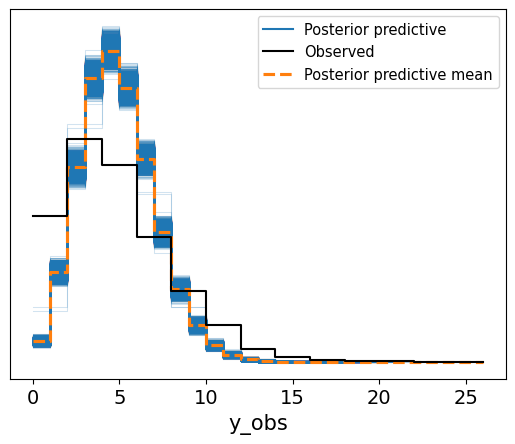

In [32]:
with model:
    ppc = pm.sample_posterior_predictive(
        trace,
        extend_inferencedata=True
    )
az.plot_ppc(ppc)

Extract Park Effect

In [33]:
beta_samples = trace.posterior["beta"].values.reshape(-1, J)

park_effects = pd.DataFrame({
    "park": parks,
    "mean": beta_samples.mean(axis=0),
    "lower": np.percentile(beta_samples, 2.5, axis=0),
    "upper": np.percentile(beta_samples, 97.5, axis=0)
})

park_effects = park_effects.sort_values("mean")

In [34]:
import plotly.graph_objects as go

# 1. Sort for readability
park_effects_sorted = park_effects.sort_values("mean").reset_index(drop=True)

# 2. Color: hitter-friendly vs pitcher-friendly parks
colors = [
    "crimson" if x > 0 else "royalblue"
    for x in park_effects_sorted["mean"]
]

# 3. Hover text (rich info)
hover_text = (
    "Park: " + park_effects_sorted["park"] +
    "<br>Mean: " + park_effects_sorted["mean"].round(3).astype(str) +
    "<br>Lower: " + park_effects_sorted["lower"].round(3).astype(str) +
    "<br>Upper: " + park_effects_sorted["upper"].round(3).astype(str)
)

# 4. Plot
fig = go.Figure()

fig.add_trace(go.Scatter(
    x=park_effects_sorted["mean"],
    y=park_effects_sorted["park"],
    mode="markers",
    marker=dict(
        color=colors,
        size=10,
        line=dict(width=1, color="black")
    ),
    error_x=dict(
        type="data",
        symmetric=False,
        array=park_effects_sorted["upper"] - park_effects_sorted["mean"],
        arrayminus=park_effects_sorted["mean"] - park_effects_sorted["lower"],
        thickness=1.5,
        width=4
    ),
    hovertext=hover_text,
    hoverinfo="text",
    name="Park Effects"
))

# 5. Reference line (no effect)
fig.add_vline(
    x=0,
    line_dash="dash",
    line_color="gray"
)

# 6. Layout improvements
fig.update_layout(
    title="MLB Ballpark Effects (Bayesian Hierarchical Model)",
    xaxis_title="Effect on Log Runs",
    yaxis_title="Ballpark",
    height=900,
    width=1100,
    template="plotly_white",
    font=dict(size=12)
)

fig.show()

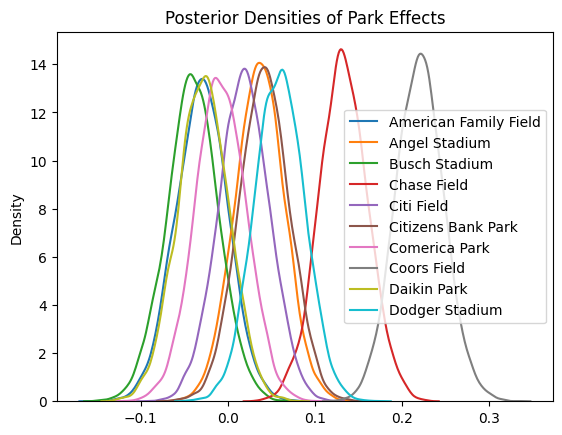

In [38]:
import seaborn as sns
import matplotlib.pyplot as plt

for i, park in enumerate(parks[:10]):  # first 10 parks
    sns.kdeplot(beta_samples[:, i], label=park)

plt.legend()
plt.title("Posterior Densities of Park Effects")
plt.show()

In [39]:
park_avg = df.groupby("venue")["runs"].mean()
league_avg = df["runs"].mean()

park_factor = park_avg / league_avg

comparison = park_effects.set_index("park")
comparison["traditional_factor"] = park_factor

print(comparison.sort_values("mean"))

                                  mean     lower     upper  traditional_factor
park                                                                          
T-Mobile Park                -0.140870 -0.203436 -0.079584            0.849699
Globe Life Field             -0.134614 -0.195633 -0.075628            0.856066
Guaranteed Rate Field        -0.096605 -0.173355 -0.023722            0.883185
Wrigley Field                -0.081484 -0.138397 -0.026023            0.908997
Progressive Field            -0.056091 -0.114327  0.000832            0.935314
PNC Park                     -0.054337 -0.112075  0.003068            0.936902
Petco Park                   -0.053241 -0.110899  0.001982            0.937880
Kauffman Stadium             -0.052527 -0.111999  0.006662            0.939211
Oracle Park                  -0.049123 -0.108041  0.008398            0.942470
Truist Park                  -0.043760 -0.100650  0.012365            0.947794
Busch Stadium                -0.040464 -0.099925  0.